# Task 4 – Video Motion Estimation (Unit 5)

**Input:** my self-recorded video `data/video.mp4`, a man breaking a coconut and moving around a new car (464×832, 30 fps, about 6 seconds)

**What this notebook does**
1. Extracts consecutive frames from the video
2. **Frame differencing** to find moving regions
3. **GMM background subtraction** (OpenCV MOG2)
4. **Lucas–Kanade optical flow** to estimate motion vectors
5. Displays foreground masks and motion vectors
6. Compares the three methods with numbers

**Important:** the phone was hand-held and moved during recording (it pans and zooms out from the crouching person to the car). Frame differencing and background subtraction both assume a **static camera**, so I also add a **camera-motion-compensated** version of frame differencing and compare all of them.

Outputs are saved to `outputs/task4/`.

## 0. Setup

In [1]:
import os
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
OUT = "outputs/task4"
FRAMES = f"{OUT}/frames"
os.makedirs(FRAMES, exist_ok=True)


def show(images, titles, cols=3, size=4.0, suptitle=None, save_as=None):
    rows = (len(images) + cols - 1) // cols
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * (size * h / w + 0.45) + 0.5))
    axes = np.array(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap=None if im.ndim == 3 else "gray")
        ax.set_title(t, fontsize=10)
    if suptitle:
        fig.suptitle(suptitle, fontsize=13)
    fig.tight_layout()
    if save_as:
        fig.savefig(f"{OUT}/{save_as}", dpi=100)
    plt.show()

## 1. Read the video and extract consecutive frames

Resolution 464x832, 30 fps, 176 frames = 5.9 seconds


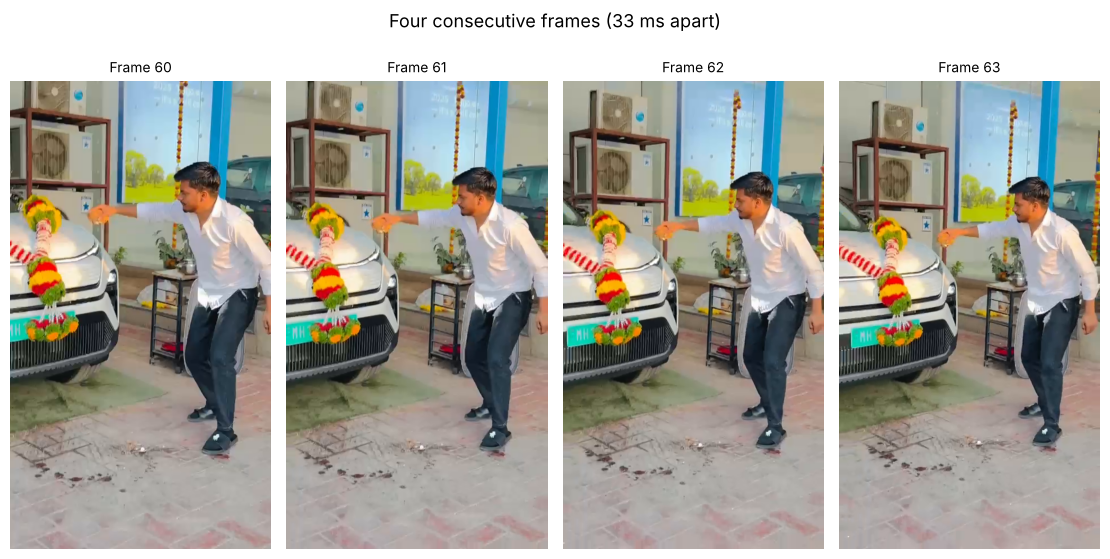

In [2]:
cap = cv2.VideoCapture("data/video.mp4")
fps = cap.get(cv2.CAP_PROP_FPS)
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frames = []
while True:
    ok, f = cap.read()
    if not ok:
        break
    frames.append(f)
cap.release()
print(f"Resolution {W}x{H}, {fps:.0f} fps, {len(frames)} frames = {len(frames) / fps:.1f} seconds")

for i in range(0, len(frames), 10):           # save every 10th frame
    cv2.imwrite(f"{FRAMES}/seq_{i:03d}.jpg", frames[i])

show(frames[60:64], [f"Frame {60 + i}" for i in range(4)], cols=4, size=2.8,
     suptitle="Four consecutive frames (33 ms apart)", save_as="fig1_consecutive_frames.png")

## 2. Helper functions
- `clean()`: morphological opening and closing to remove speckle from a binary mask.
- `person_box()`: YOLO's "person" box in each frame, used as **approximate ground truth** for where the moving object is. This lets me score the masks with numbers:
  - **Precision:** what share of the detected foreground pixels lies inside the person box (high means few false alarms)
  - **Coverage:** what share of the person box is marked as foreground (high means the object is found well)

In [3]:
K = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
yolo = YOLO("yolov8n.pt")


def clean(mask):
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, K)
    return cv2.morphologyEx(mask, cv2.MORPH_CLOSE, K, iterations=2)


def person_box(frame):
    r = yolo(frame, conf=0.3, classes=[0], verbose=False)[0]    # COCO class 0 = person
    if len(r.boxes) == 0:
        return None
    return tuple(map(int, r.boxes[int(r.boxes.conf.argmax())].xyxy[0]))


def score(mask, box):
    x1, y1, x2, y2 = box
    fg = mask > 0
    inside, total = fg[y1:y2, x1:x2].sum(), fg.sum()
    return (inside / total if total else 0.0,                # precision
            inside / max((x2 - x1) * (y2 - y1), 1),          # coverage
            100 * total / fg.size)                           # % of frame marked as moving


def overlay(frame, mask, col):
    o = frame.copy()
    o[mask > 0] = (0.5 * o[mask > 0] + 0.5 * np.array(col)).astype(np.uint8)
    return o

## 3. Method 1 – Frame differencing
The simplest motion detector: take the absolute difference between two consecutive grayscale frames, |Iₜ − Iₜ₋₁|, and threshold it (here at 25). Pixels that changed are marked as "moving".

**Camera-motion-compensated version:** I track corner points with LK, estimate the global camera motion between the two frames as an affine transform (with RANSAC to ignore the moving person), and **warp the previous frame to line up with the current one** before taking the difference. Only the object's own motion should then remain.

In [4]:
DIFF_T = 25


def frame_difference(prev_g, gray):
    d = cv2.absdiff(gray, prev_g)
    _, m = cv2.threshold(d, DIFF_T, 255, cv2.THRESH_BINARY)
    return clean(m)


def camera_motion(prev_g, gray):
    p0 = cv2.goodFeaturesToTrack(prev_g, 400, 0.01, 8)
    p1, st, _ = cv2.calcOpticalFlowPyrLK(prev_g, gray, p0, None)
    ok = st.ravel() == 1
    M, _ = cv2.estimateAffinePartial2D(p0[ok], p1[ok], method=cv2.RANSAC, ransacReprojThreshold=3)
    return M


def compensated_difference(prev_g, gray):
    M = camera_motion(prev_g, gray)
    aligned = cv2.warpAffine(prev_g, M, (W, H), borderMode=cv2.BORDER_REPLICATE) if M is not None else prev_g
    d = cv2.absdiff(gray, aligned)
    _, m = cv2.threshold(d, DIFF_T, 255, cv2.THRESH_BINARY)
    return clean(m)

## 4. Method 2 – GMM background subtraction (MOG2)
MOG2 models **each pixel's history as a mixture of Gaussians** (Gaussian Mixture Model). Values that fit the frequent, stable Gaussians are background; values that don't fit are foreground. The model updates over time (`history=100` frames), so it adapts to slow lighting changes. It also detects shadows (value 127), which I discard.

In [5]:
def new_mog2():
    return cv2.createBackgroundSubtractorMOG2(history=100, varThreshold=25, detectShadows=True)


def mog2_mask(model, frame):
    fg = model.apply(frame)
    return clean(np.where(fg == 255, 255, 0).astype(np.uint8))   # drop shadows (127)

## 5. Method 3 – Lucas–Kanade optical flow
Lucas–Kanade estimates how small patches move between frames:
- It assumes **brightness constancy** (a point keeps its intensity) and **small motion**, and that all pixels in a small window (21×21) move together, then solves for the (u, v) motion by least squares.
- It is applied to good corner points (Shi–Tomasi `goodFeaturesToTrack`), so it is **sparse** optical flow.
- An image pyramid (`maxLevel=3`) handles larger motions.

Arrows are drawn 3× longer than the actual motion so they are visible. I also subtract the **median flow** (the camera motion) to get each point's *own* motion.

In [6]:
def lk_flow(prev_g, gray, frame):
    p0 = cv2.goodFeaturesToTrack(prev_g, maxCorners=300, qualityLevel=0.01, minDistance=7, blockSize=7)
    p1, st, _ = cv2.calcOpticalFlowPyrLK(prev_g, gray, p0, None, winSize=(21, 21), maxLevel=3,
                                          criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
    ok = st.ravel() == 1
    a, b = p0[ok].reshape(-1, 2), p1[ok].reshape(-1, 2)
    vis = frame.copy()
    for (x0, y0), (x1, y1) in zip(a, b):
        end = (int(x0 + 3 * (x1 - x0)), int(y0 + 3 * (y1 - y0)))
        cv2.arrowedLine(vis, (int(x0), int(y0)), end, (0, 255, 255), 2, tipLength=0.3)
        cv2.circle(vis, (int(x1), int(y1)), 2, (0, 0, 255), -1)
    return vis, a, b

## 6. Run all methods on the whole video
This loop processes every frame and:
- computes the masks and flow,
- scores them against the YOLO person box (skipping the first 30 frames while MOG2 learns the background),
- writes a side-by-side comparison video `motion_comparison.mp4`,
- stores four example frames for display.

In [7]:
mog2 = new_mog2()
writer = cv2.VideoWriter(f"{OUT}/motion_comparison.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (W * 2, H // 2))
showcase = set(np.linspace(20, len(frames) - 10, 4).astype(int))
stats = {"diff": [], "comp": [], "mog2": []}
times = {"diff": [], "comp": [], "mog2": [], "lk": []}
flow_stats, panels = [], []
prev_g = None

for idx, frame in enumerate(frames):
    gray = cv2.GaussianBlur(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    t = time.perf_counter(); fg = mog2_mask(mog2, frame); times["mog2"].append(time.perf_counter() - t)
    if prev_g is None:
        prev_g = gray
        continue

    t = time.perf_counter(); diff = frame_difference(prev_g, gray); times["diff"].append(time.perf_counter() - t)
    t = time.perf_counter(); comp = compensated_difference(prev_g, gray); times["comp"].append(time.perf_counter() - t)
    t = time.perf_counter(); flow_vis, a, b = lk_flow(prev_g, gray, frame); times["lk"].append(time.perf_counter() - t)

    box = person_box(frame)
    if box is not None and idx > 30:
        for k, m in [("diff", diff), ("comp", comp), ("mog2", fg)]:
            stats[k].append(score(m, box))
        v = b - a
        x1, y1, x2, y2 = box
        inside = (b[:, 0] >= x1) & (b[:, 0] <= x2) & (b[:, 1] >= y1) & (b[:, 1] <= y2)
        cam = np.median(v, axis=0)
        if inside.any() and (~inside).any():
            mag, resid = np.linalg.norm(v, axis=1), np.linalg.norm(v - cam, axis=1)
            flow_stats.append([mag[inside].mean(), mag[~inside].mean(),
                               resid[inside].mean(), resid[~inside].mean(), np.linalg.norm(cam)])

    tiles = [overlay(frame, diff, (0, 0, 255)), overlay(frame, comp, (0, 255, 0)), overlay(frame, fg, (255, 0, 0)), flow_vis]
    names = ["Frame diff", "Diff + cam. comp.", "GMM (MOG2)", "Lucas-Kanade"]
    small = []
    for tl, nm in zip(tiles, names):
        tl = cv2.resize(tl, (W // 2, H // 2))
        cv2.putText(tl, nm, (8, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
        small.append(tl)
    writer.write(np.hstack(small))

    if idx in showcase:
        bx = frame.copy()
        if box:
            cv2.rectangle(bx, box[:2], box[2:], (255, 120, 0), 3)
        for name, im in [("diff_mask", diff), ("diffcomp_mask", comp), ("mog2_mask", fg), ("lk_flow", flow_vis)]:
            cv2.imwrite(f"{OUT}/f{idx:03d}_{name}.{'jpg' if name == 'lk_flow' else 'png'}", im)
        panels.append((idx, [bx, diff, comp, fg, flow_vis]))
    prev_g = gray

writer.release()
print("Processed", len(frames), "frames; comparison video saved to", f"{OUT}/motion_comparison.mp4")

Processed 176 frames; comparison video saved to outputs/task4/motion_comparison.mp4


## 7. Foreground masks and motion vectors

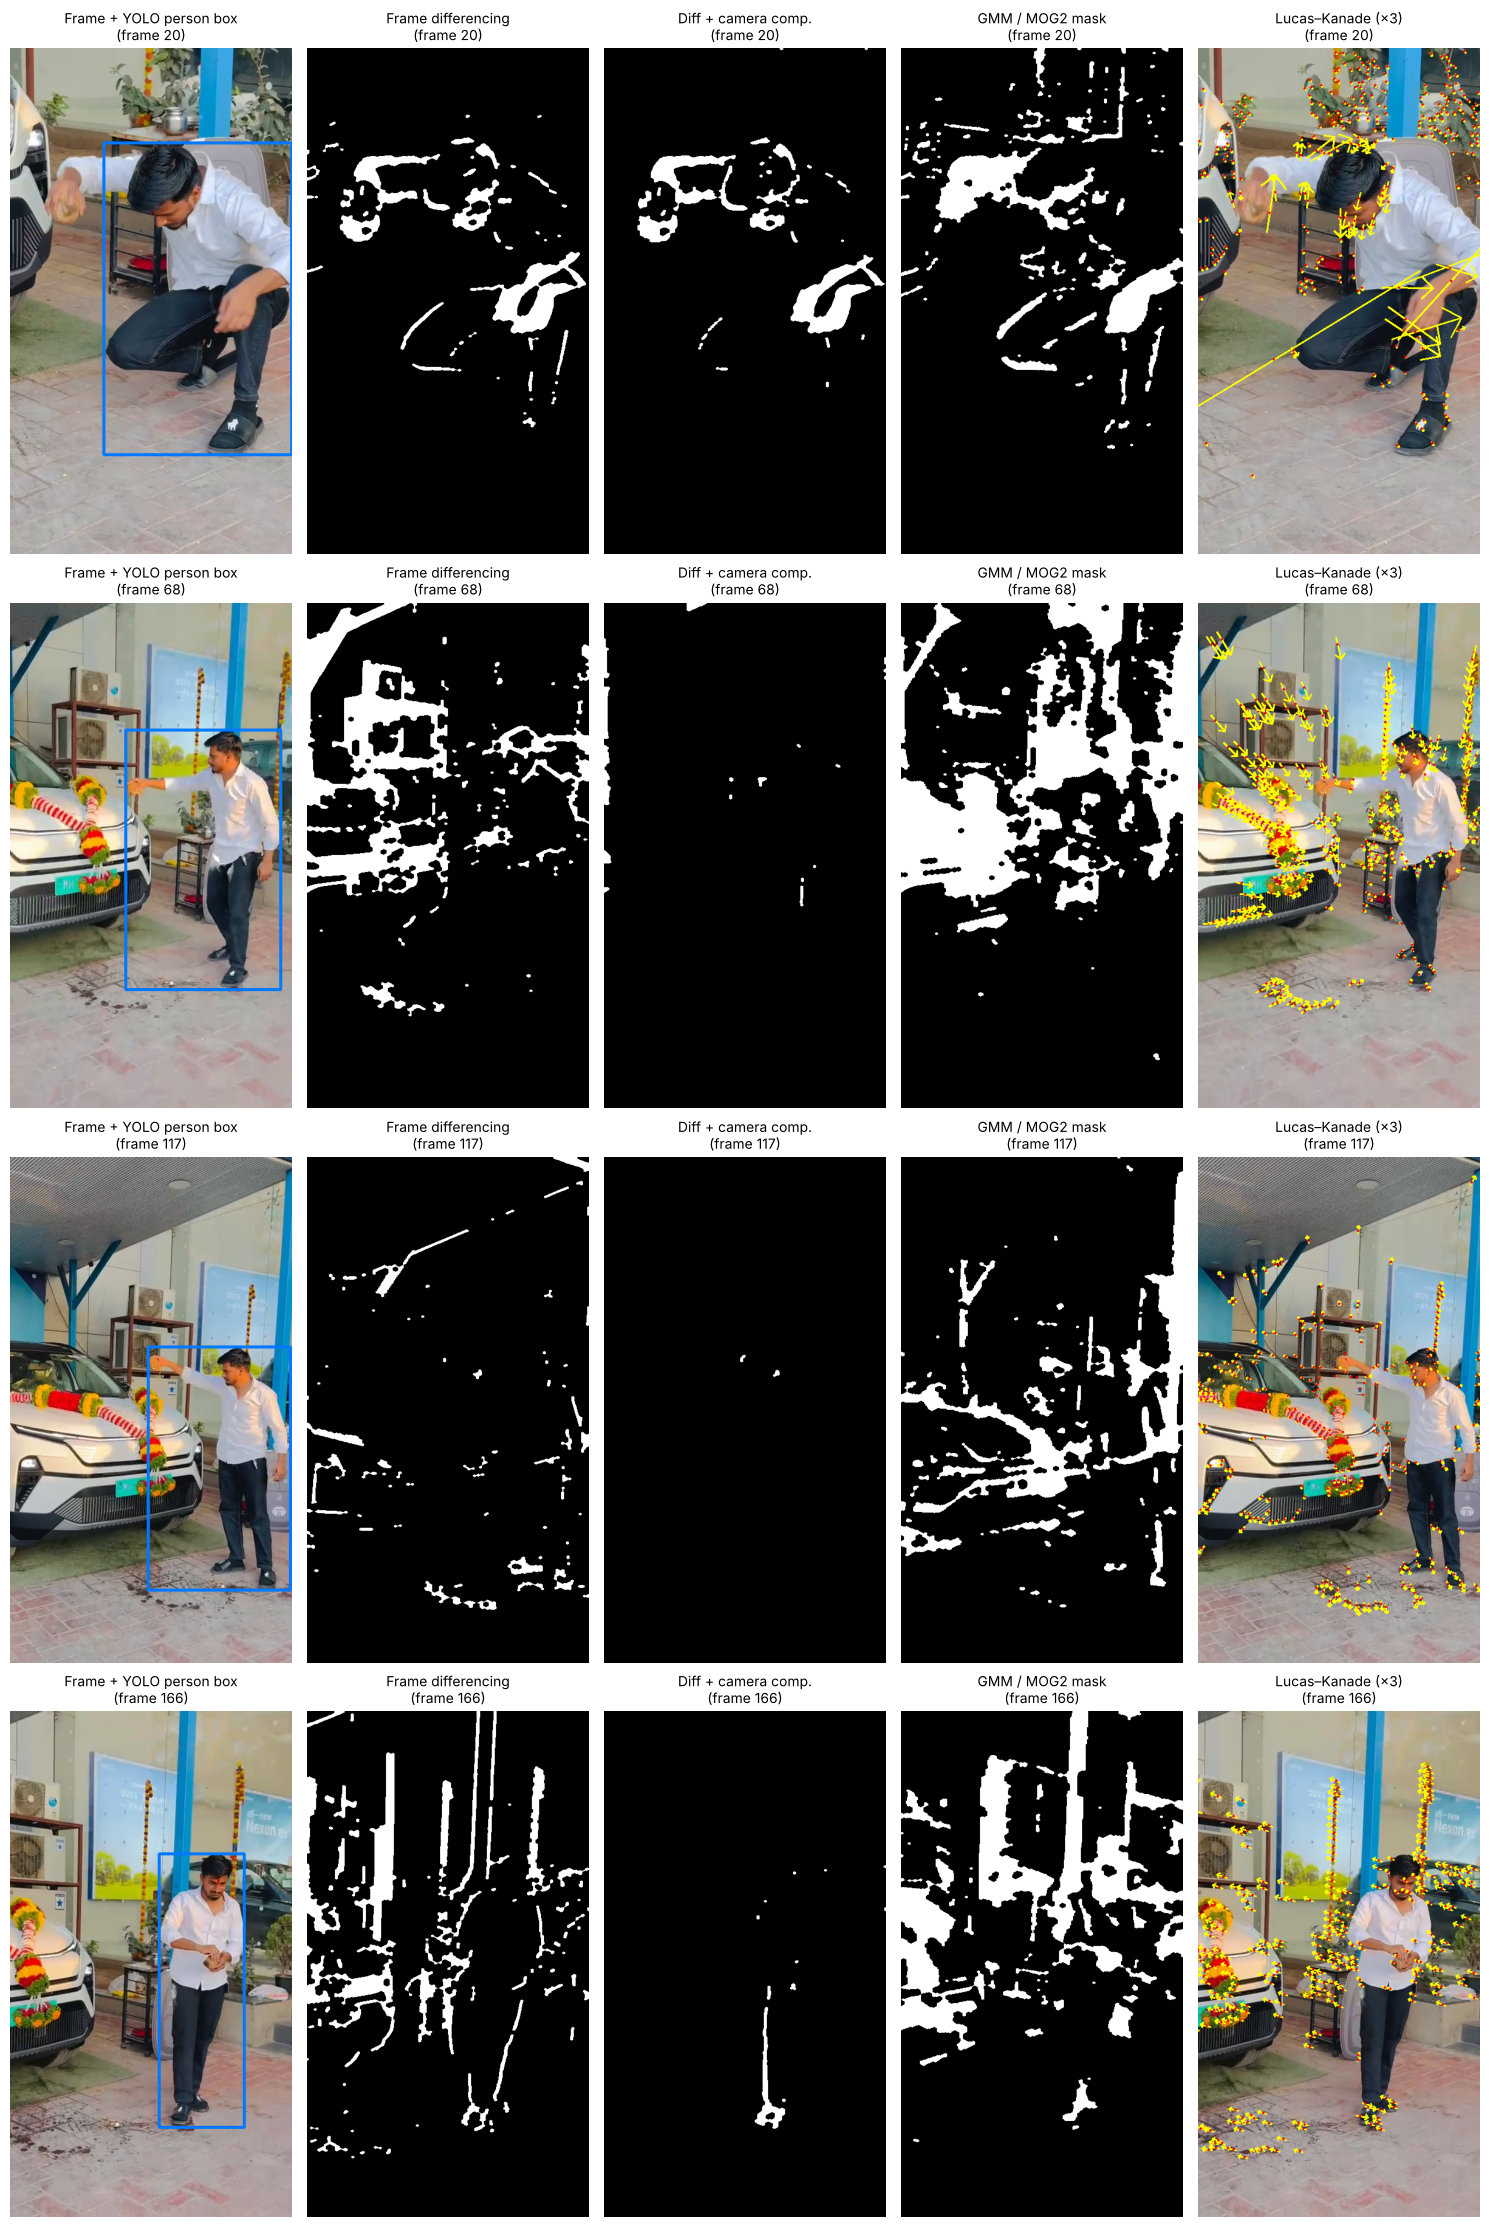

In [8]:
cols = ["Frame + YOLO person box", "Frame differencing", "Diff + camera comp.", "GMM / MOG2 mask", "Lucas–Kanade (×3)"]
fig, axes = plt.subplots(len(panels), 5, figsize=(15, 5.6 * len(panels)))
for r, (i, ims) in enumerate(panels):
    for c, im in enumerate(ims):
        ax = axes[r, c]
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap="gray")
        ax.set_title(f"{cols[c]}\n(frame {i})", fontsize=10); ax.axis("off")
fig.tight_layout(); fig.savefig(f"{OUT}/fig2_motion_comparison.png", dpi=90); plt.show()

**What the masks show:**
- **Frame 20** (person throwing the coconut, fast arm movement): all three methods highlight the **moving arm, head and legs**. Frame differencing marks only the *edges* of the moving parts, because the inside of the uniform white shirt doesn't change between frames. Lucas–Kanade shows long arrows on the arm and leg (fast motion). A few very long arrows are tracking errors, where the motion is too large for LK's small-motion assumption.
- **Frames 68 and 117** (camera panning and zooming out): plain frame differencing and MOG2 mark large parts of the **AC unit, the wall, the car and the garland** as moving, because every background pixel shifts when the camera moves. The **compensated** difference removes almost all of this.
- **Frame 166** (person standing almost still): there is very little real motion. Plain differencing and MOG2 still show the background "moving" (vertical poles and the banner). The compensated version keeps only a thin trace near the legs.
- **Lucas–Kanade:** in the panning frames, the arrows on the background (AC unit, garland, poles) all point the same way, which is the camera motion.

## 8. Comparison table

In [9]:
label = {"diff": "Frame differencing", "comp": "Frame diff + camera compensation", "mog2": "GMM background subtraction (MOG2)"}
rows = []
for k, v in stats.items():
    a = np.array(v)
    rows.append([label[k], round(a[:, 2].mean(), 1), round(100 * a[:, 0].mean(), 1),
                 round(100 * a[:, 1].mean(), 1), round(1000 * np.mean(times[k]), 1)])
table_motion = pd.DataFrame(rows, columns=["Method", "Foreground area (% of frame)",
                                           "Precision – FG inside person box (%)", "Coverage of person box (%)",
                                           "Time per frame (ms)"])
table_motion.to_csv(f"{OUT}/table_motion.csv", index=False)
table_motion

,Method,Foreground area (% of frame),Precision – FG inside person box (%),Coverage of person box (%),Time per frame (ms)
0,Frame differencing,7.8,33.5,7.3,0.7
1,Frame diff + camera compensation,1.6,77.6,3.6,11.8
2,GMM background subtraction (MOG2),16.1,35.2,19.9,20.2


In [10]:
fs = np.array(flow_stats).mean(axis=0)
table_flow = pd.DataFrame([
    ["Raw flow (includes camera motion)", round(fs[0], 1), round(fs[1], 1), round(fs[0] / fs[1], 2)],
    ["After subtracting camera motion", round(fs[2], 1), round(fs[3], 1), round(fs[2] / fs[3], 2)],
], columns=["Lucas–Kanade", "Mean motion on person (px/frame)", "Mean motion on background (px/frame)", "Person / background ratio"])
table_flow.to_csv(f"{OUT}/table_optical_flow.csv", index=False)
print(f"Average camera motion: {fs[4]:.1f} px per frame;  LK time: {1000 * np.mean(times['lk']):.1f} ms per frame")
table_flow

Average camera motion: 4.1 px per frame;  LK time: 10.0 ms per frame


,Lucas–Kanade,Mean motion on person (px/frame),Mean motion on background (px/frame),Person / background ratio
0,Raw flow (includes camera motion),4.3,5.4,0.80
1,After subtracting camera motion,3.1,2.1,1.51


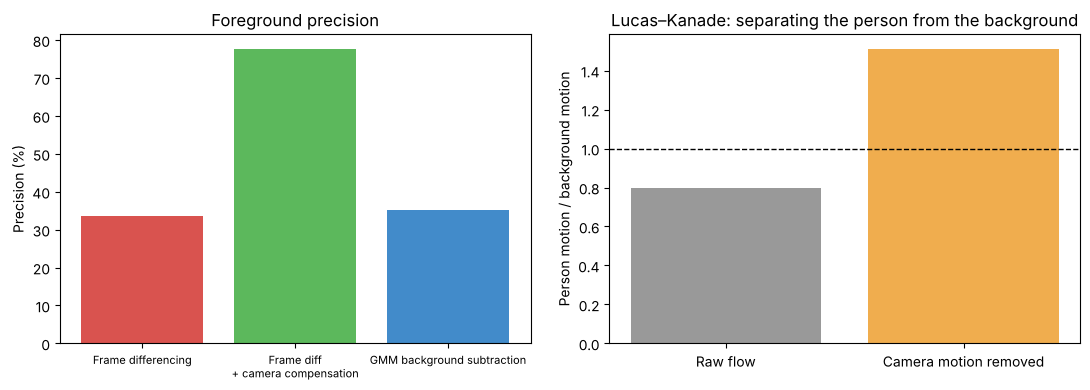

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(table_motion["Method"].str.replace(" (MOG2)", "").str.replace(" + ", "\n+ "), table_motion["Precision – FG inside person box (%)"], color=["#d9534f", "#5cb85c", "#428bca"])
ax[0].set_ylabel("Precision (%)"); ax[0].set_title("Foreground precision"); ax[0].tick_params(axis="x", labelsize=8)
ax[1].bar(["Raw flow", "Camera motion removed"], table_flow["Person / background ratio"], color=["#999999", "#f0ad4e"])
ax[1].axhline(1, ls="--", c="k", lw=1); ax[1].set_ylabel("Person motion / background motion")
ax[1].set_title("Lucas–Kanade: separating the person from the background")
fig.tight_layout(); fig.savefig(f"{OUT}/fig3_motion_metrics.png", dpi=110); plt.show()

## 9. Discussion and comparison

| Method | How it works | Strengths | Weaknesses (seen in my video) |
|---|---|---|---|
| Frame differencing | Subtract consecutive frames and threshold | Fastest (under 1 ms per frame), no training, instant response | Finds only *edges* of moving parts; the camera pan makes the whole background look like it's moving (precision about 34%) |
| Frame diff + camera compensation | Align frames first (affine from LK + RANSAC) | **Highest precision (about 78%)**: almost no false background motion | Very low coverage (about 4%). After alignment only the fast-moving parts remain; slow or uniform body regions disappear |
| GMM / MOG2 | Per-pixel Gaussian mixture background model | **Highest coverage (about 20%)**: fills more of the person, handles shadows | Needs a static camera and warm-up frames; with camera motion, large background areas become "foreground" (precision about 35%) |
| Lucas–Kanade optical flow | Solve brightness constancy in small windows at corner points | Gives motion **direction and speed**; separates camera motion from object motion | Sparse (only at corners); fails on very fast motion (long wrong arrows in frame 20); plain shirt has few corners |

**Conclusion:** in a hand-held video, methods that assume a static background (frame differencing and MOG2) produce many false detections, because they can't tell camera motion from object motion. **Optical flow is the most informative**: before removing camera motion the person seems to move *less* than the background (ratio 0.8). After subtracting the camera motion (median flow), the person moves about **1.5×** more than the background. Using the same flow to align frames gives the most precise mask, but it only keeps the fast-moving parts. There is a **trade-off between precision (compensated differencing) and coverage (MOG2)**. With the phone kept on a stand, MOG2 would give the most complete silhouette of the person.